# Neural Networks – 1st Assignment

A deep CNN with 3 convolutional blocks, trained in PyTorch to classify the CIFAR-10 images.

It uses data augmentation, Batch Normalization, Dropout and a cosine learning-rate schedule, and the last cells show the training curves, the test results and examples of correct and wrong predictions.

In [1]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, accuracy_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR # <--- the scheduler

import torchvision
import torchvision.transforms as T

print("PyTorch version:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.9.0+cu126
Using device: cuda


In [2]:
# CELL 2: FULL AUGMENTATION

cifar_mean = [0.4914, 0.4822, 0.4465]
cifar_std  = [0.2023, 0.1994, 0.2010]

train_transform = T.Compose([
    # 1. Geometric changes
    T.RandomHorizontalFlip(p=0.5),
    T.RandomCrop(32, padding=4),

    # 2. Conversion
    T.ToTensor(),

    # 3. Changes on the tensor (Normalize + Erasing)
    T.Normalize(cifar_mean, cifar_std),
    T.RandomErasing(p=0.5, scale=(0.02, 0.33), ratio=(0.3, 3.3)) # <-- ERASING HAPPENS HERE
])

val_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(cifar_mean, cifar_std)
])

# --- Datasets & Loaders ---
full_train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=val_transform)

batch_size = 64
val_pct = 0.1
val_size = int(len(full_train_dataset) * val_pct)
train_size = len(full_train_dataset) - val_size

val_dataset_clean = torchvision.datasets.CIFAR10(root='./data', train=True, download=False, transform=val_transform)

train_dataset, _ = random_split(full_train_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42))
_, val_dataset = random_split(val_dataset_clean, [train_size, val_size], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train size: {len(train_dataset)} (Augmented with Erase)")
print(f"Val size: {len(val_dataset)}")

100%|██████████| 170M/170M [00:05<00:00, 30.2MB/s]


Train size: 45000 (Augmented with Erase)
Val size: 5000


In [3]:
# Cell 3: 3-BLOCK CNN (DEEPER & WIDER)

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # --- Block 1 (64 filters) ---
        self.conv1 = nn.Conv2d(3, 64, 3, padding=1)
        self.bn1   = nn.BatchNorm2d(64)
        self.conv2 = nn.Conv2d(64, 64, 3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)
        self.pool1 = nn.MaxPool2d(2,2) # 32x32 -> 16x16
        self.drop1 = nn.Dropout(0.3)

        # --- Block 2 (128 filters) ---
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 128, 3, padding=1)
        self.bn4   = nn.BatchNorm2d(128)
        self.pool2 = nn.MaxPool2d(2,2) # 16x16 -> 8x8
        self.drop2 = nn.Dropout(0.3)

        # --- Block 3 (NEW: 256 filters) ---
        self.conv5 = nn.Conv2d(128, 256, 3, padding=1)
        self.bn5   = nn.BatchNorm2d(256)
        self.conv6 = nn.Conv2d(256, 256, 3, padding=1)
        self.bn6   = nn.BatchNorm2d(256)
        self.pool3 = nn.MaxPool2d(2,2) # 8x8 -> 4x4
        self.drop3 = nn.Dropout(0.4)

        # --- Fully Connected ---
        self.flatten = nn.Flatten()
        # Input: 256 filters * 4 * 4 = 4096
        self.fc1 = nn.Linear(256 * 4 * 4, 512) # FC layer enlarged to 512
        self.bnfc = nn.BatchNorm1d(512)
        self.dropfc = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        # Block 1
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool1(x)
        x = self.drop1(x)

        # Block 2
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.pool2(x)
        x = self.drop2(x)

        # Block 3
        x = F.relu(self.bn5(self.conv5(x)))
        x = F.relu(self.bn6(self.conv6(x)))
        x = self.pool3(x)
        x = self.drop3(x)

        # FC
        x = self.flatten(x)
        x = F.relu(self.bnfc(self.fc1(x)))
        x = self.dropfc(x)
        x = self.fc2(x)
        return x

model = SimpleCNN(num_classes=10).to(device)
print(model)

SimpleCNN(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop1): Dropout(p=0.3, inplace=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop2): Dropout(p=0.3, inplace=False)
  (conv5): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padd

In [4]:
# Cell 4

TOTAL_EPOCHS = 80

criterion = nn.CrossEntropyLoss()

optimizer = Adam(model.parameters(),
                 lr=1e-3,
                 weight_decay=1e-5)

scheduler = CosineAnnealingLR(optimizer, T_max=TOTAL_EPOCHS)

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for Xb, yb in loader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer.zero_grad()
        outputs = model(Xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * Xb.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == yb).sum().item()
        total += yb.size(0)
    return running_loss / total, correct / total

def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for Xb, yb in loader:
            Xb, yb = Xb.to(device), yb.to(device)
            outputs = model(Xb)
            loss = criterion(outputs, yb)
            running_loss += loss.item() * Xb.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == yb).sum().item()
            total += yb.size(0)
            all_preds.append(preds.cpu().numpy())
            all_labels.append(yb.cpu().numpy())
    return running_loss / total, correct / total, np.concatenate(all_preds), np.concatenate(all_labels)

In [5]:
# Cell 5: Training

history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
print(f"Starting training for {TOTAL_EPOCHS} epochs...")

for epoch in range(1, TOTAL_EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Epoch {epoch}/{TOTAL_EPOCHS} - train_acc: {train_acc:.4f} - val_acc: {val_acc:.4f} - val_loss: {val_loss:.4f} - LR: {optimizer.param_groups[0]['lr']:.6f}")
    scheduler.step()

print("Training finished.")

Starting training for 80 epochs...
Epoch 1/80 - train_acc: 0.4465 - val_acc: 0.5778 - val_loss: 1.1625 - LR: 0.001000
Epoch 2/80 - train_acc: 0.5922 - val_acc: 0.6170 - val_loss: 1.1349 - LR: 0.001000
Epoch 3/80 - train_acc: 0.6501 - val_acc: 0.6920 - val_loss: 0.8627 - LR: 0.000998
Epoch 4/80 - train_acc: 0.6799 - val_acc: 0.7562 - val_loss: 0.6813 - LR: 0.000997
Epoch 5/80 - train_acc: 0.7036 - val_acc: 0.7906 - val_loss: 0.5899 - LR: 0.000994
Epoch 6/80 - train_acc: 0.7237 - val_acc: 0.7694 - val_loss: 0.6766 - LR: 0.000990
Epoch 7/80 - train_acc: 0.7333 - val_acc: 0.8092 - val_loss: 0.5541 - LR: 0.000986
Epoch 8/80 - train_acc: 0.7467 - val_acc: 0.8134 - val_loss: 0.5217 - LR: 0.000981
Epoch 9/80 - train_acc: 0.7583 - val_acc: 0.8204 - val_loss: 0.5017 - LR: 0.000976
Epoch 10/80 - train_acc: 0.7698 - val_acc: 0.8412 - val_loss: 0.4627 - LR: 0.000969
Epoch 11/80 - train_acc: 0.7786 - val_acc: 0.8422 - val_loss: 0.4635 - LR: 0.000962
Epoch 12/80 - train_acc: 0.7858 - val_acc: 0.8484 

Running final evaluation on Test Set...

Final Test Loss: 0.2621
Final Test Accuracy: 0.9237

Classification Report:
               precision    recall  f1-score   support

           0     0.9283    0.9320    0.9301      1000
           1     0.9670    0.9660    0.9665      1000
           2     0.9316    0.8720    0.9008      1000
           3     0.8582    0.8110    0.8339      1000
           4     0.8961    0.9400    0.9175      1000
           5     0.8796    0.8770    0.8783      1000
           6     0.9205    0.9720    0.9455      1000
           7     0.9558    0.9510    0.9534      1000
           8     0.9521    0.9540    0.9530      1000
           9     0.9459    0.9620    0.9539      1000

    accuracy                         0.9237     10000
   macro avg     0.9235    0.9237    0.9233     10000
weighted avg     0.9235    0.9237    0.9233     10000



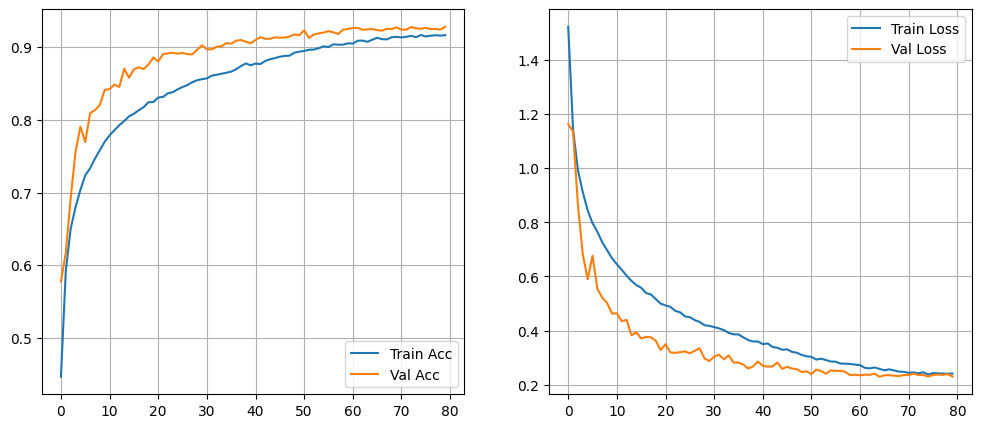

In [6]:
# Cell 6
print("Running final evaluation on Test Set...")
test_loss, test_acc, test_preds, test_labels = evaluate(model, test_loader, criterion, device)
print(f"\nFinal Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_acc:.4f}")
print("\nClassification Report:\n", classification_report(test_labels, test_preds, digits=4))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history['train_acc'], label='Train Acc')
plt.plot(history['val_acc'], label='Val Acc')
plt.legend(); plt.grid()
plt.subplot(1, 2, 2)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.legend(); plt.grid()
plt.show()


--- Correct Predictions ---

--- Incorrect Predictions ---


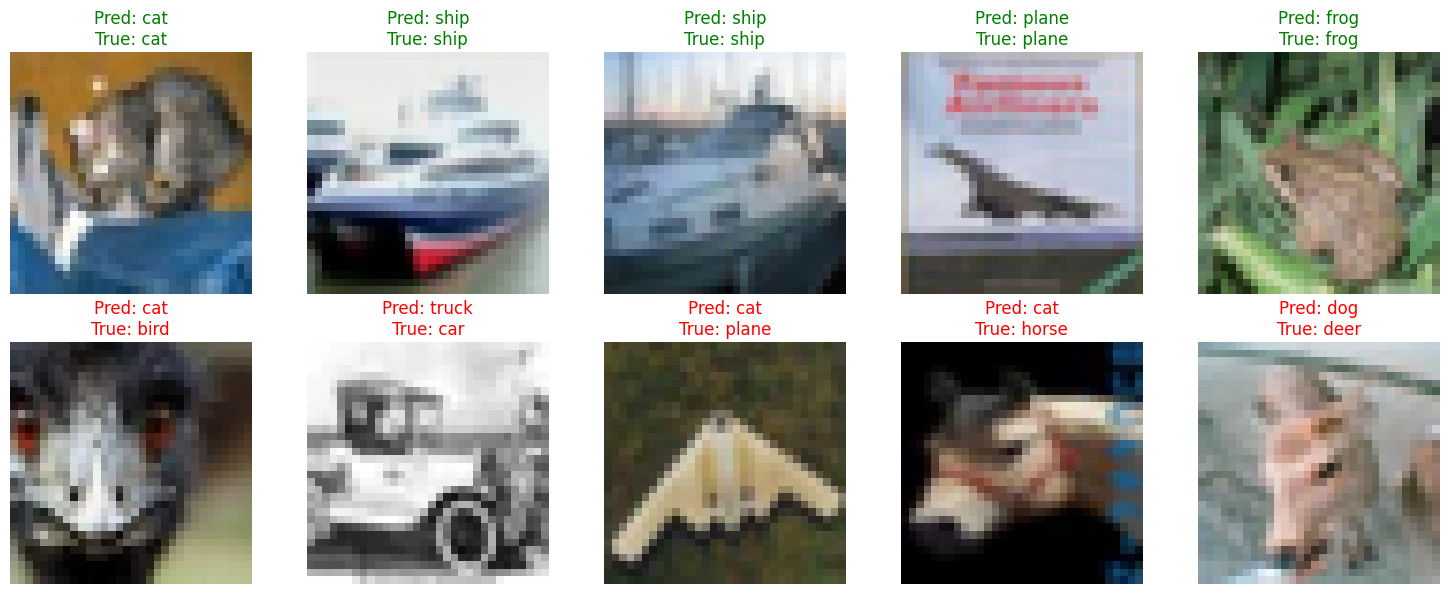

In [7]:
# Cell: show correct and wrong predictions

def show_predictions(model, loader, device, num_images=5):
    model.eval()
    images_so_far = 0
    fig = plt.figure(figsize=(15, 6))

    classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

    # Lists to keep some examples
    correct_examples = []
    incorrect_examples = []

    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            outputs = model(X)
            _, preds = torch.max(outputs, 1)

            for i in range(len(y)):
                # Un-normalize the image so it displays properly
                # (x * std) + mean
                img = X[i].cpu().numpy().transpose((1, 2, 0))
                mean = np.array([0.4914, 0.4822, 0.4465])
                std = np.array([0.2023, 0.1994, 0.2010])
                img = std * img + mean
                img = np.clip(img, 0, 1)

                if preds[i] == y[i] and len(correct_examples) < num_images:
                    correct_examples.append((img, preds[i].item(), y[i].item()))
                elif preds[i] != y[i] and len(incorrect_examples) < num_images:
                    incorrect_examples.append((img, preds[i].item(), y[i].item()))

            if len(correct_examples) >= num_images and len(incorrect_examples) >= num_images:
                break

    # Plot Correct
    print("\n--- Correct Predictions ---")
    for i in range(num_images):
        img, pred, true = correct_examples[i]
        ax = plt.subplot(2, num_images, i + 1)
        plt.imshow(img)
        ax.set_title(f"Pred: {classes[pred]}\nTrue: {classes[true]}", color='green')
        plt.axis('off')

    # Plot Incorrect
    print("\n--- Incorrect Predictions ---")
    for i in range(num_images):
        img, pred, true = incorrect_examples[i]
        ax = plt.subplot(2, num_images, num_images + i + 1)
        plt.imshow(img)
        ax.set_title(f"Pred: {classes[pred]}\nTrue: {classes[true]}", color='red')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

show_predictions(model, test_loader, device)